# Notebook 08: Hyperparameter Tuning

## Objective
Tune the baseline Random Forest classifier for imbalanced credit-card fraud detection.

## Tuning strategy
- Use the existing training partition for model fitting.
- Use the validation partition to compare configurations.
- Optimize Macro F1.
- Also monitor balanced accuracy, fraud precision, fraud recall and fraud F1.
- Keep the test partition untouched for final evaluation.

The experiment uses a small manual hyperparameter search to control computational cost.

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

print("Imports successful.")

Imports successful.


In [2]:
PROJECT_DIR = os.path.dirname(os.getcwd())

PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
REPORTS_DIR = os.path.join(PROJECT_DIR, "reports")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /Users/jasmithav/isfe_creditcard_project


In [3]:
X_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "X_train.csv")
).values

X_val = pd.read_csv(
    os.path.join(PROCESSED_DIR, "X_val.csv")
).values

y_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_train.csv")
).values.ravel()

y_val = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_val.csv")
).values.ravel()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

print("Training fraud cases:", np.sum(y_train == 1))
print("Validation fraud cases:", np.sum(y_val == 1))

Training: (182276, 30)
Validation: (45570, 30)
Training fraud cases: 315
Validation fraud cases: 79


In [4]:
def evaluate_model(model, X, y):
    predictions = model.predict(X)

    return {
        "Accuracy": accuracy_score(y, predictions),
        "Macro F1": f1_score(y, predictions, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y, predictions),
        "Fraud Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Fraud Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "Fraud F1": f1_score(
            y, predictions, zero_division=0
        )
    }

print("Evaluation function ready.")

Evaluation function ready.


In [5]:
configurations = [
    {
        "name": "RF_100_Trees",
        "n_estimators": 100,
        "max_depth": None,
        "min_samples_leaf": 1
    },
    {
        "name": "RF_200_Trees",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1
    },
    {
        "name": "RF_Depth_20",
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 1
    },
    {
        "name": "RF_Leaf_2",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 2
    }
]

print("Configurations to evaluate:", len(configurations))

Configurations to evaluate: 4


In [6]:
tuning_results = []
trained_models = {}

for config in configurations:
    name = config["name"]

    print(f"\nTraining {name}...")

    model = RandomForestClassifier(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        min_samples_leaf=config["min_samples_leaf"],
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    metrics = evaluate_model(model, X_val, y_val)

    result = {
        "Model": name,
        **metrics,
        "Training Time (s)": training_time
    }

    tuning_results.append(result)
    trained_models[name] = model

    print(
        f"Macro F1: {metrics['Macro F1']:.4f} | "
        f"Balanced Accuracy: {metrics['Balanced Accuracy']:.4f} | "
        f"Fraud Recall: {metrics['Fraud Recall']:.4f} | "
        f"Time: {training_time:.2f}s"
    )

print("\nAll configurations evaluated.")


Training RF_100_Trees...
Macro F1: 0.9361 | Balanced Accuracy: 0.9113 | Fraud Recall: 0.8228 | Time: 36.43s

Training RF_200_Trees...
Macro F1: 0.9361 | Balanced Accuracy: 0.9113 | Fraud Recall: 0.8228 | Time: 48.07s

Training RF_Depth_20...
Macro F1: 0.9361 | Balanced Accuracy: 0.9113 | Fraud Recall: 0.8228 | Time: 40.19s

Training RF_Leaf_2...
Macro F1: 0.9361 | Balanced Accuracy: 0.9113 | Fraud Recall: 0.8228 | Time: 44.44s

All configurations evaluated.


In [7]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by=["Macro F1", "Training Time (s)"],
    ascending=[False, True]
).reset_index(drop=True)

display(tuning_df.round(6))

tuning_df.to_csv(
    os.path.join(REPORTS_DIR, "hyperparameter_tuning_results.csv"),
    index=False
)

print("Tuning results saved.")

,Model,Accuracy,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1,Training Time (s)
0,RF_100_Trees,0.999583,0.936137,0.911337,0.928571,0.822785,0.872483,36.433484
1,RF_Depth_20,0.999583,0.936137,0.911337,0.928571,0.822785,0.872483,40.191315
2,RF_Leaf_2,0.999583,0.936137,0.911337,0.928571,0.822785,0.872483,44.435411
3,RF_200_Trees,0.999583,0.936137,0.911337,0.928571,0.822785,0.872483,48.068810


Tuning results saved.


In [8]:
best_model_name = tuning_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_model_path = os.path.join(
    MODELS_DIR,
    "tuned_random_forest.joblib"
)

joblib.dump(best_model, best_model_path)

with open(
    os.path.join(REPORTS_DIR, "best_tuned_model.txt"),
    "w"
) as f:
    f.write(best_model_name)

print("Selected model:", best_model_name)
print("Saved model:", best_model_path)

Selected model: RF_100_Trees
Saved model: /Users/jasmithav/isfe_creditcard_project/models/tuned_random_forest.joblib


In [9]:
best_predictions = best_model.predict(X_val)

print("Selected model:", best_model_name)
print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        best_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

Selected model: RF_100_Trees

Classification Report:

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     45491
       Fraud       0.93      0.82      0.87        79

    accuracy                           1.00     45570
   macro avg       0.96      0.91      0.94     45570
weighted avg       1.00      1.00      1.00     45570



In [10]:
baseline_results = pd.read_csv(
    os.path.join(REPORTS_DIR, "baseline_results.csv")
)

baseline_rf = baseline_results[
    baseline_results["Model"].str.contains(
        "Random Forest", case=False, na=False
    )
]

tuned_metrics = evaluate_model(best_model, X_val, y_val)

comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        **{
            key: float(baseline_rf.iloc[0][key])
            for key in [
                "Accuracy",
                "Macro F1",
                "Balanced Accuracy",
                "Fraud Precision",
                "Fraud Recall",
                "Fraud F1"
            ]
        }
    },
    {
        "Model": "Tuned Random Forest",
        **tuned_metrics
    }
])

display(comparison.round(6))

comparison.to_csv(
    os.path.join(REPORTS_DIR, "baseline_vs_tuned_rf.csv"),
    index=False
)

,Model,Accuracy,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,Baseline Random Forest,0.999583,0.936137,0.911337,0.928571,0.822785,0.872483
1,Tuned Random Forest,0.999583,0.936137,0.911337,0.928571,0.822785,0.872483


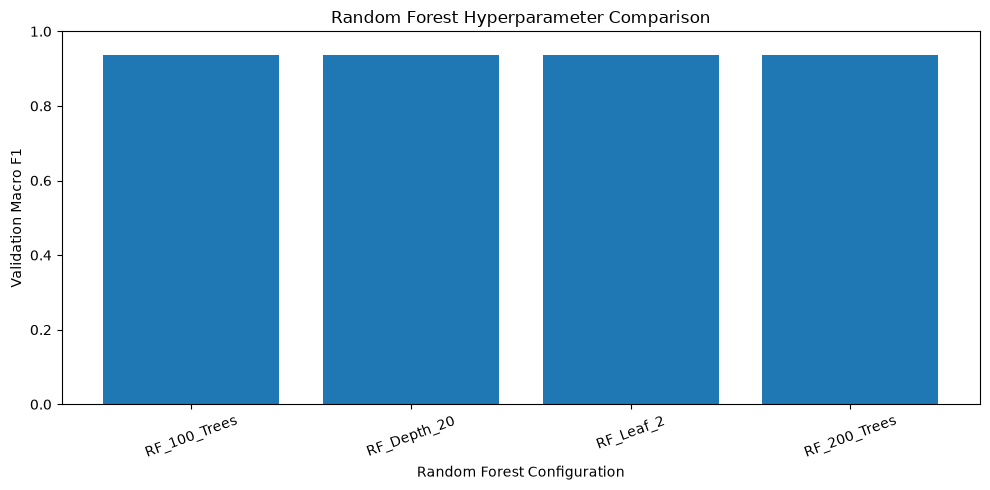

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    tuning_df["Model"],
    tuning_df["Macro F1"]
)

plt.ylabel("Validation Macro F1")
plt.xlabel("Random Forest Configuration")
plt.title("Random Forest Hyperparameter Comparison")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    os.path.join(REPORTS_DIR, "hyperparameter_comparison.png"),
    dpi=300
)

plt.show()